In [1]:
# @title Install 
!pip install tikzplotlib 
import abc 
import numpy as np 
import pandas as pd
import joblib as jlb
import seaborn as sns
from operator import add 
import tikzplotlib as tkz
import tqdm.notebook as tqdm 
import matplotlib.pyplot as plt 
from joblib import Parallel, delayed
from functools import reduce, partial
from IPython.display import clear_output
%matplotlib inline 

In [17]:
#@title  Set up 
class BernoulliBandit(object):
    r"""Implement a Bernoulli bandit"""

    def __init__(self, K=2, arms_means=None, D=1) -> None:
        r"""
        @constructor
        Parameters
        ----------
        K: int > 0
           Number of arms of the bandit
        arms_means: np.ndarray of shape [K, d]
           Mean reward of each arm
        D: int>0
           Dimension of the reward vector
                """
        self.D = D if arms_means is None else [*np.shape(arms_means), 1][1]
        self.arms_means = np.random.uniform(size=(K, self.D)) if arms_means is None else np.asarray(arms_means)
        self.arms_means = self.arms_means.reshape(-1, self.D).squeeze(-1) if self.D == 1 else self.arms_means
        super(BernoulliBandit, self).__init__()

    def sample(self, arms):
        r"""
         Sample from a Bernoulli bandit
         Parameters
         -----------
         arms : set  of arms to sample
         Returns
         ------
         Samples from arms
         Test
         ----
         >>> bernoulli_bandit = BernoulliBandit(K=10)
         >>> bernoulli_bandit.sample([1,2,4])
         """
        arms = [arms] if isinstance(arms, int) else arms
        return np.random.binomial(1, self.arms_means[arms]).reshape(-1, self.D)
    
def M(X_i,X_j):
  return np.max(X_i - X_j, -1)
def m(X_i,X_j):
  return np.min(X_j - X_i, -1)
def beta_ij(T_i, T_j):
  return 0.5*np.sqrt(
      2*(
          2*(np.log(K*(K-1)*D/(2*delta))/2 + np.log(np.log(K*(K-1)*D/(2*delta))/2)) + 2*np.log(4+ np.log(T_i)) + 2*np.log(4+ np.log(T_j)) 
      )*(
          (1/T_i) + (1/T_j)
      )
  )

def beta(T_i, delta_=None):
  delta_ = delta/K/D if delta_ is None else delta_
  return 0.5*np.sqrt((2*np.log(1/delta_) + max(6*np.log(np.log(1/delta_)), 0) + 3*np.log(np.log(np.e*T_i))) /  T_i)

In [18]:
#@title Bandit instance
K = 10
D = 1 
delta = 0.01
inf = (1<<31)*1.
arms_means = np.random.uniform(0, 1, size=K).reshape(-1)
best_arm = np.argmax(arms_means)
pareto_arms = set([best_arm])
Deltas = np.max(arms_means) - arms_means
Deltas[Deltas==0] = np.inf 
Deltas[Deltas==np.inf]= np.min(Deltas)
H = sum(1/Deltas**2)*0.5 #subgaussian proxy
bandit = BernoulliBandit(arms_means=arms_means)
print(best_arm)
print(H*np.log(1/(2.4*delta)), H)
arms_means

9
1994.3852446576025 534.7305332945461


array([0.2607893 , 0.53337664, 0.60640098, 0.42862911, 0.270513  ,
       0.2274008 , 0.01550271, 0.87559034, 0.59689447, 0.91963784])

In [19]:
# @title ape
def ape(seed):
  inf = (1<<31)*1.
  np.random.seed(seed)
  arms = np.arange(K)
  total = np.zeros((K, D))
  #initialize bandit 
  total[arms] += bandit.sample(arms)
  Nc = np.ones(K, dtype=int)
  mus = total/Nc[:, None]
  xt = mus.reshape(-1)
  I = np.eye(K)
  z1_t = lambda : min([min(xt[i]-xt - beta_ij(Nc[i], Nc) + inf*I[i])  for i in a_star_t])
  a_star_t = [np.argmax(xt)]
  while z1_t() < 0:
    bt = np.argmax([min(- xt  + beta_ij(Nc[i], Nc) + inf*I[i]) + xt[i]  for i in arms])
    ct = np.argmax(xt + beta_ij(Nc[bt], Nc) - inf*I[bt])
    idx = [bt, ct]
    idx = [idx[np.argmin(Nc[idx])]]
    for a in idx: 
      total[a] += bandit.sample([a]).reshape(-1)
      Nc[a] += 1  
    mus = total/Nc[:, None]
    xt = mus.reshape(-1)
    a_star_t = [np.argmax(xt)]
  return set(pareto_arms)==(set(a_star_t)), Nc.sum()

In [20]:
# @title lucb
def lucb(seed):
  np.random.seed(seed)
  Nc = np.zeros(K, dtype=int)
  arms = np.arange(K)
  total = np.zeros((K, D))
  #initialize bandit 
  total[arms] += bandit.sample(arms)
  Nc = np.ones(K, dtype=int)
  mus = total/Nc[:, None]
  I = np.eye(K)
  x_t = mus.reshape(-1)
  ht = np.argmax(x_t)
  lt = np.argmax(x_t + beta(Nc) - inf*I[ht])
  stop = ((x_t[lt] + beta(Nc[lt])) - (x_t[ht] - beta(Nc[ht])))< 0
  while not stop:
      ht = np.argmax(x_t)
      lt = np.argmax(x_t + beta(Nc) - inf*I[ht])
      for i in [lt, ht]:
        total[i] += bandit.sample([i]).reshape(-1)
        Nc[i] += 1
      mus = total / Nc[:,None]
      x_t = mus.reshape(-1) 
      ht = np.argmax(x_t)
      lt = np.argmax(x_t + beta(Nc) - inf*I[ht])
      stop = ((x_t[lt] + beta(Nc[lt])) - (x_t[ht] - beta(Nc[ht])))< 0
  return set([ht]) == set(pareto_arms), Nc.sum()

In [21]:
# @title lucb++
def lucbpp(seed):
  np.random.seed(seed)
  Nc = np.zeros(K, dtype=int)
  arms = np.arange(K)
  total = np.zeros((K, D))
  #initialize bandit 
  total[arms] += bandit.sample(arms)
  Nc = np.ones(K, dtype=int)
  mus = total/Nc[:, None]
  x_t = mus.reshape(-1)
  I = np.eye(K)
  ht = np.argmax(x_t)
  lt = np.argmax(x_t + beta(Nc) - inf*I[ht])
  stop = ((x_t[lt] + beta(Nc[lt], delta/2)) - (x_t[ht] - beta(Nc[ht], delta/(2*(K-1)))))< 0
  while not stop:
      ht = np.argmax(x_t)
      lt = np.argmax(x_t + beta(Nc, delta/2) - inf*I[ht])
      for i in [lt, ht]:
        total[i] += bandit.sample([i]).reshape(-1)
        Nc[i] += 1
      mus = total / Nc[:,None]
      x_t = mus.reshape(-1) 
      ht = np.argmax(x_t)
      lt = np.argmax(x_t + beta(Nc, delta/2) - inf*I[ht])
      stop = ((x_t[lt] + beta(Nc[lt], delta/2)) - (x_t[ht] - beta(Nc[ht], delta/(2*(K-1)))))< 0
  return set([ht]) == set(pareto_arms), Nc.sum()

In [22]:
# @title ugape
def ugape(seed):
  np.random.seed(seed)
  Nc = np.zeros(K, dtype=int)
  arms = np.arange(K)
  total = np.zeros((K, D))
  #initialize bandit 
  total[arms] += bandit.sample(arms)
  Nc = np.ones(K, dtype=int)
  mus = total/Nc[:, None]
  x_t = mus.reshape(-1)
  I = np.eye(K)
  ht = np.argmin([np.max(x_t + beta(Nc) -inf*I[i]) - (x_t[i] - beta(Nc[i])) for i in arms])
  lt = np.argmax(x_t + beta(Nc) -inf*I[ht])
  stop = ((x_t[lt] + beta(Nc[lt])) - (x_t[ht] - beta(Nc[ht])))< 0
  while not stop:
      ht = np.argmin([max(x_t + beta(Nc) -inf*I[i]) - (x_t[i] - beta(Nc[i])) for i in arms])
      lt = np.argmax(x_t + beta(Nc) -inf*I[ht])
      idx = [ht, lt]
      idx = [idx[np.argmax(beta(Nc[idx]))]]
      for i in idx:
        total[i] += bandit.sample([i]).reshape(-1)
        Nc[i]+= 1
      mus = total / Nc[:,None]
      x_t = mus.reshape(-1) 
      ht = np.argmin([np.max(x_t + beta(Nc) -inf*I[i]) - (x_t[i] - beta(Nc[i])) for i in arms])
      lt = np.argmax(x_t + beta(Nc) -inf*I[ht])
      stop = ((x_t[lt] + beta(Nc[lt])) - (x_t[ht] - beta(Nc[ht])))< 0
  return set([ht]) == set(pareto_arms), Nc.sum()

In [23]:
numiter = 1000
seeds = (np.random.uniform(size=numiter)*2**31).astype(int)

In [ ]:
res_lucbpp = Parallel(n_jobs=-1, verbose=1)(delayed(lucbpp)(i) for i in seeds)
res_lucbpp = np.array(res_lucbpp).T

In [ ]:
print(np.mean(res_lucbpp[1]), np.mean(res_lucbpp[0]))

In [438]:
res_lucb = Parallel(n_jobs=-1, verbose=1)(delayed(lucb)(i) for i in seeds)
res_lucb = np.array(res_lucb).T

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    1.6s
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed:    7.9s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:   18.7s
[Parallel(n_jobs=-1)]: Done 784 tasks      | elapsed:   33.8s
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:   43.0s finished


In [439]:
print(np.mean(res_lucb[1]), np.mean(res_lucb[0]))

11908.046 1.0


In [440]:
res_ape = Parallel(n_jobs=-1, verbose=1)(delayed(ape)(i) for i in seeds)
res_ape = np.array(res_ape).T 

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:    7.4s
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed:   37.3s
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 784 tasks      | elapsed:  2.6min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  3.3min finished


In [441]:
print(np.mean(res_ape[1]), np.mean(res_ape[0]))

8138.381 1.0


In [442]:
res_ugape = Parallel(n_jobs=-1, verbose=1)(delayed(ugape)(i) for i in seeds)
res_ugape = np.array(res_ugape).T

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:   19.5s
[Parallel(n_jobs=-1)]: Done 184 tasks      | elapsed:  1.7min
[Parallel(n_jobs=-1)]: Done 434 tasks      | elapsed:  3.9min
[Parallel(n_jobs=-1)]: Done 784 tasks      | elapsed:  7.0min
[Parallel(n_jobs=-1)]: Done 1000 out of 1000 | elapsed:  8.9min finished


In [443]:
print(np.mean(res_ugape[1]), np.mean(res_ugape[0]))

11789.861 1.0


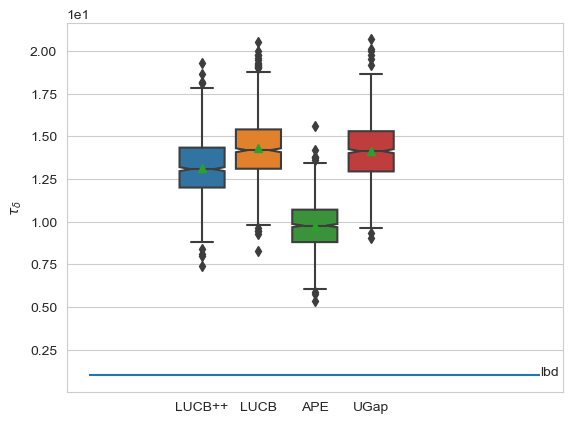

In [445]:
sns.set_style('whitegrid')
data = np.concatenate((res_lucbpp[1], res_lucb[1], res_ape[1], res_ugape[1])) / (H*np.log(1/(2.4*delta)))
names = reduce(add, [[txt,]*len(seeds) for txt in [r"LUCB++", r"LUCB", r"APE", r"UGap"]])
df = pd.DataFrame({"sc": data, "names": names})
fig = sns.boxplot(data=df, x="names", y="sc",  orient="v", showmeans=True, showfliers=True, notch=True)
fig.set_xlabel('',fontweight='bold')
fig.set_ylabel(r'$\tau_{\delta}$')
fig.text(6, 1, "lbd")
plt.hlines(1, -2, 6)
plt.ticklabel_format(axis="y", style="sci", scilimits=(0,0))
plt.show()